# Despliegue

> En este notebook preparamos lo que necesita la app de Streamlit: cargamos el modelo `champion` desde el Model Registry, calculamos los embeddings de todo el catálogo para buscar productos parecidos y probamos la búsqueda. La app está en `app/streamlit_app.py`.

**Objetivos:**
1. Cargar el modelo `champion` desde el Model Registry de MLflow.
2. Calcular los embeddings de las imágenes del catálogo.
3. Probar la búsqueda de productos similares.
4. Lanzar la app.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import DataLoader

from fashion_mlops.config import PROCESSED_DATA_DIR, IMAGES_DIR, RANDOM_STATE
from fashion_mlops.data.dataset import FashionDataset, get_transforms
from fashion_mlops.models.train import get_device
from fashion_mlops.models.predict import load_champion_model, get_champion_version, predict_image
from fashion_mlops.models.embeddings import (
    get_feature_extractor, compute_embeddings, embed_image, find_similar, embeddings_path
)

## Modelo champion

Cargamos el modelo que tiene el alias `champion` en el Model Registry. No necesitamos saber de qué experimento viene: eso lo decidimos en `05_mlflow`.

In [2]:
model, classes = load_champion_model()
champion = get_champion_version()

print(f"Modelo: versión {champion.version} (run {champion.tags.get('run_name')})")
print(f"F1-macro en validación: {champion.tags.get('val_f1_macro')} | en test: {champion.tags.get('test_f1_macro')}")
print(f"Clases: {classes}")

Modelo: versión 2 (run fine_tuning_30ep)
F1-macro en validación: 0.8467 | en test: 0.8995
Clases: ['Accessories', 'Apparel', 'Footwear', 'Other', 'Personal Care']


## Embeddings del catálogo

Para recomendar productos parecidos a la imagen que sube el usuario, quitamos la última capa del modelo. Así, en lugar de las probabilidades de cada clase, el modelo devuelve un vector de 512 números (embedding) que resume el aspecto de la imagen. Dos productos parecidos tendrán vectores parecidos, y lo medimos con la similitud coseno.

Calculamos el embedding de todas las imágenes del catálogo y lo guardamos. Si en el futuro cambia el modelo `champion`, hay que volver a ejecutar esta celda (el fichero lleva el número de versión del modelo).

In [3]:
df = pd.read_csv(PROCESSED_DATA_DIR / "styles_splits.csv")

extractor = get_feature_extractor(model)
device = get_device()

loader = DataLoader(
    FashionDataset(df, IMAGES_DIR, label_col="masterCategory_idx", transform=get_transforms(train=False)),
    batch_size=128,
    num_workers=4,
)

embeddings = compute_embeddings(extractor, loader, device)

np.savez(embeddings_path(champion.version), ids=df["id"].to_numpy(), embeddings=embeddings)

print(f"Embeddings: {embeddings.shape} guardados en {embeddings_path(champion.version).name}")

Embeddings: (44414, 512) guardados en embeddings_v2.npz


## Búsqueda de productos similares

Probamos con algunas imágenes de test: predecimos su categoría y buscamos los productos más parecidos dentro de esa categoría (quitando la propia imagen):

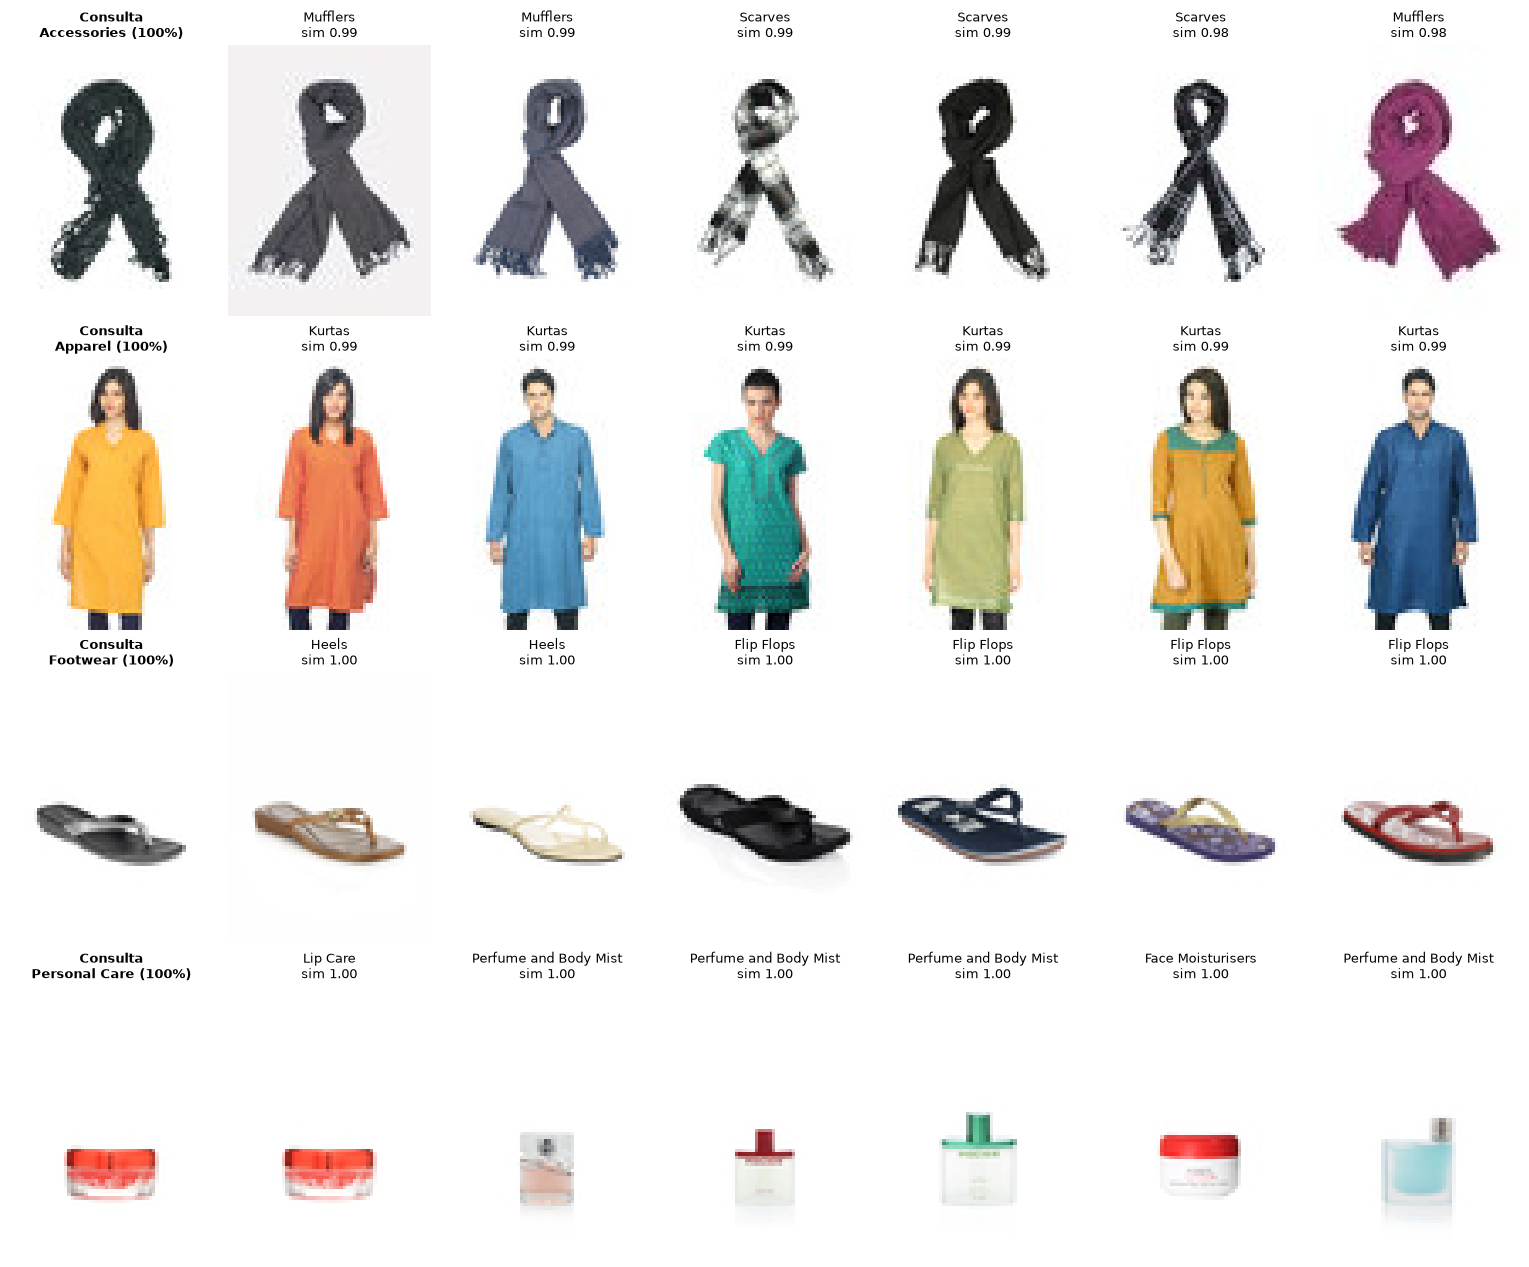

In [4]:
queries = df[df["split"] == "test"].groupby("masterCategory_grouped").sample(1, random_state=RANDOM_STATE)
queries = queries[queries["masterCategory_grouped"] != "Other"]

n_similar = 6
fig, axes = plt.subplots(len(queries), n_similar + 1, figsize=(2.2 * (n_similar + 1), 3.2 * len(queries)))

for row, (_, query) in zip(axes, queries.iterrows()):
    image = Image.open(IMAGES_DIR / f"{query['id']}.jpg")
    probs = predict_image(model, image, classes)
    pred = next(iter(probs))

    mask = (df["masterCategory_grouped"] == pred) & (df["id"] != query["id"])
    similar, similarity = find_similar(embed_image(extractor, image), embeddings, k=n_similar, mask=mask.to_numpy())

    row[0].imshow(image)
    row[0].set_title(f"Consulta\n{pred} ({probs[pred]:.0%})", fontsize=9, fontweight="bold")

    for ax, idx, sim in zip(row[1:], similar, similarity):
        ax.imshow(Image.open(IMAGES_DIR / f"{df.iloc[idx]['id']}.jpg"))
        ax.set_title(f"{df.iloc[idx]['articleType']}\nsim {sim:.2f}", fontsize=9)

    for ax in row:
        ax.axis("off")

plt.tight_layout()
plt.show()

Los productos que devuelve son del mismo tipo que la consulta (bufandas, kurtas, chanclas, cosméticos), aunque no siempre del mismo color: el modelo se fija sobre todo en la forma del producto, que es lo que ha aprendido para clasificar.

## La app

La app está en `app/streamlit_app.py` y se lanza desde la raíz del proyecto con:

```bash
uv run streamlit run app/streamlit_app.py
```

Se abre en el navegador (http://localhost:8501) y permite:
- Dar la imagen de un producto de cuatro formas: subiéndola, pegando su enlace, pegándola desde el portapapeles (Cmd+V) o probando con una imagen aleatoria del conjunto de test. Se analiza siempre la última.
- Ver la categoría predicha y la probabilidad de cada clase. Si el modelo no está seguro, lo avisa.
- Ver los productos del catálogo más parecidos dentro de la categoría predicha.

La app usa siempre el modelo `champion` del Model Registry: si en `05_mlflow` se registra un modelo mejor, la app lo usa sin cambiar el código (solo hay que recalcular los embeddings con este notebook).

## Resumen

- Cargamos el modelo `champion` (versión 2, fine-tuning de 30 épocas, F1-macro 0,899 en test) directamente desde el Model Registry.
- Hemos calculado los embeddings de las 44.414 imágenes del catálogo y los hemos guardado con el número de versión del modelo (`embeddings_v2.npz`).
- La búsqueda de productos parecidos funciona bien: devuelve productos del mismo tipo que la consulta.
- La app de Streamlit junta todo: clasifica la imagen que da el usuario y le muestra productos parecidos del catálogo, siempre con el modelo que esté marcado como `champion`.

Con esto tenemos el pipeline completo: datos (`01`-`03`), entrenamiento y registro de experimentos (`04`), selección y registro del modelo (`05`) y despliegue en una app (`06`).